In [4]:
# 1. Imports
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, random
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

Matplotlib is building the font cache; this may take a moment.


In [8]:
# 2. Load and explore data
df = pd.read_csv("../data/customer_support.csv")
print(df.shape, df.isna().sum().sum(), df.message.duplicated().sum())
print(df.category.value_counts())                      # 200 per class
print(df.message.str.split().str.len().describe())     # message length
print("Share with placeholders:", df.message.str.contains(r"\{\{").mean())

(2200, 2) 0 0
category
PAYMENT         200
ORDER           200
REFUND          200
INVOICE         200
CONTACT         200
DELIVERY        200
FEEDBACK        200
SHIPPING        200
SUBSCRIPTION    200
ACCOUNT         200
CANCEL          200
Name: count, dtype: int64
count    2200.000000
mean        8.951364
std         2.437560
min         1.000000
25%         7.000000
50%         9.000000
75%        11.000000
max        16.000000
Name: message, dtype: float64
Share with placeholders: 0.13272727272727272


In [9]:
# 3. Split 80/20, stratified
X_train, X_test, y_train, y_test = train_test_split(
    df.message, df.category, test_size=0.2, stratify=df.category, random_state=42)

In [10]:
# 4. TF-IDF + five models (pipeline = vectorizer is fitted on training data only)
models = {
    "Dummy (baseline)": DummyClassifier(strategy="most_frequent"),
    "MultinomialNB": MultinomialNB(),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}
labels = sorted(df.category.unique())
rows, fitted = [], {}
for name, clf in models.items():
    pipe = make_pipeline(TfidfVectorizer(lowercase=True), clf).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=labels)
    off = cm.copy(); np.fill_diagonal(off, 0)
    pair = max(((off[i, j] + off[j, i], labels[i], labels[j])
                for i in range(len(labels)) for j in range(i + 1, len(labels))))
    cv = cross_val_score(make_pipeline(TfidfVectorizer(), clf), df.message, df.category,
                         cv=StratifiedKFold(10, shuffle=True, random_state=42)).mean()
    rows.append([name, accuracy_score(y_test, pred), f1_score(y_test, pred, average="weighted"),
                 cv, f"{pair[1]} / {pair[2]} ({pair[0]} errors)" if pair[0] else "-"])
    fitted[name] = (pipe, pred, cm)
results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Weighted F1", "10-fold CV acc.", "Most confused pair"])
results.round(3).to_csv("../outputs/results.csv", index=False)
print(results.round(3))

              Model  Accuracy  Weighted F1  10-fold CV acc.  \
0  Dummy (baseline)     0.091        0.015            0.091   
1     MultinomialNB     0.995        0.995            0.986   
2      DecisionTree     0.941        0.942            0.946   
3      RandomForest     0.986        0.986            0.982   
4         KNN (k=5)     0.984        0.984            0.975   

                   Most confused pair  
0  ACCOUNT / SUBSCRIPTION (40 errors)  
1       ACCOUNT / SHIPPING (1 errors)  
2          CONTACT / ORDER (5 errors)  
3        FEEDBACK / REFUND (1 errors)  
4    REFUND / SUBSCRIPTION (2 errors)  


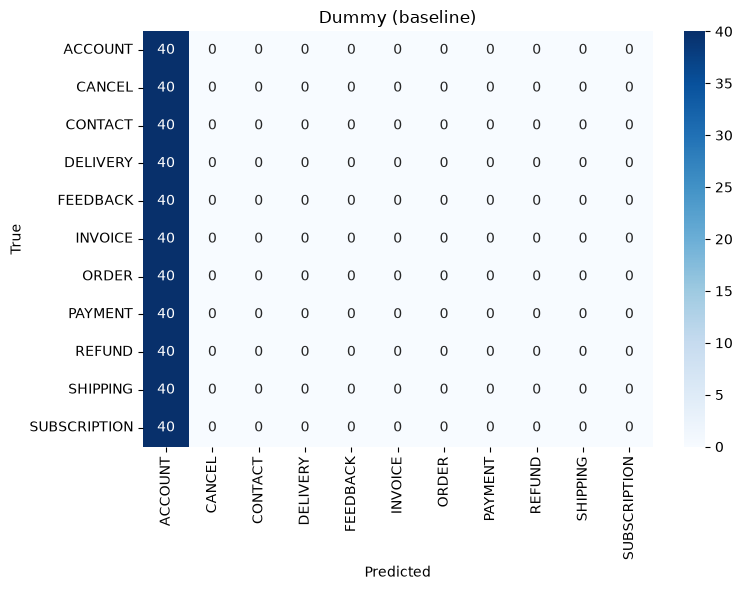

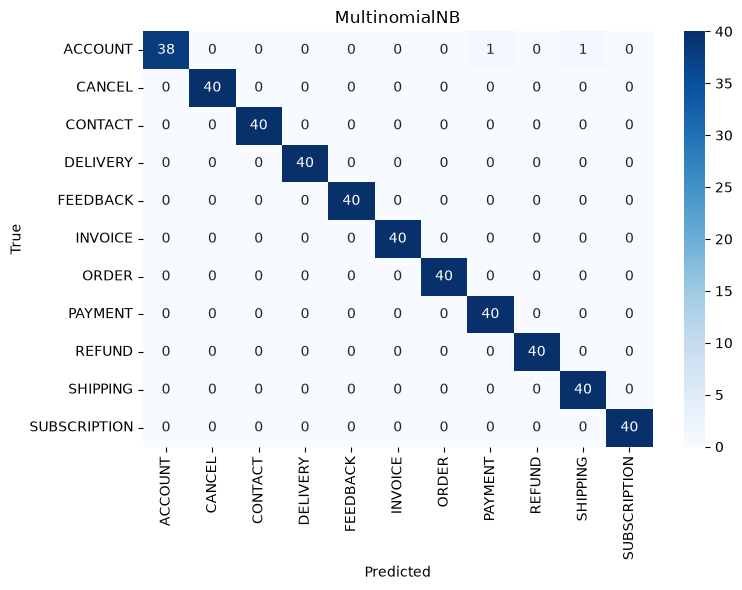

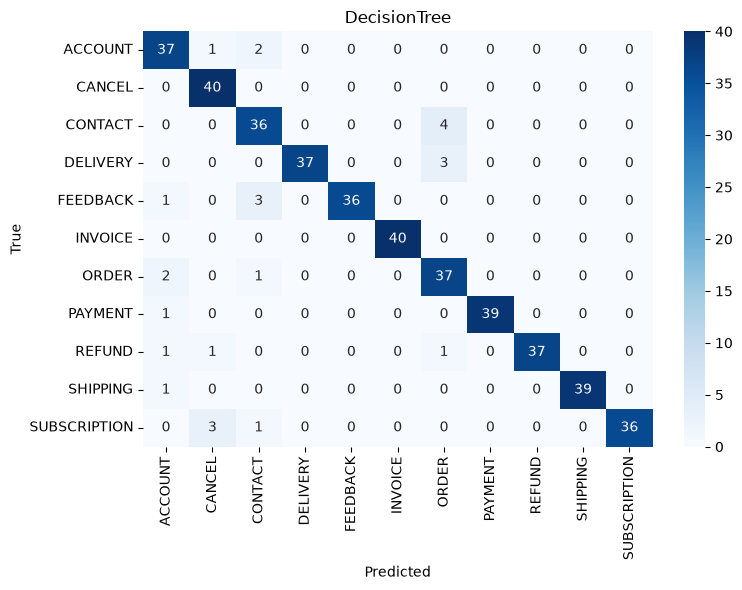

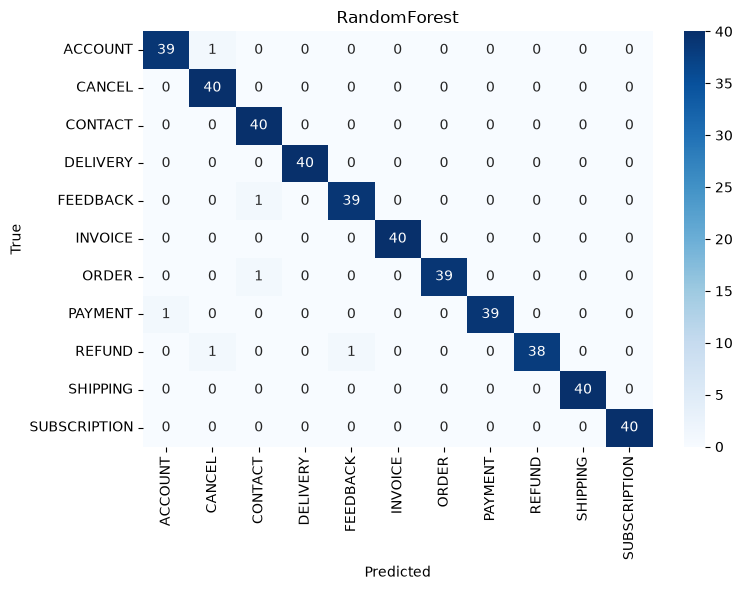

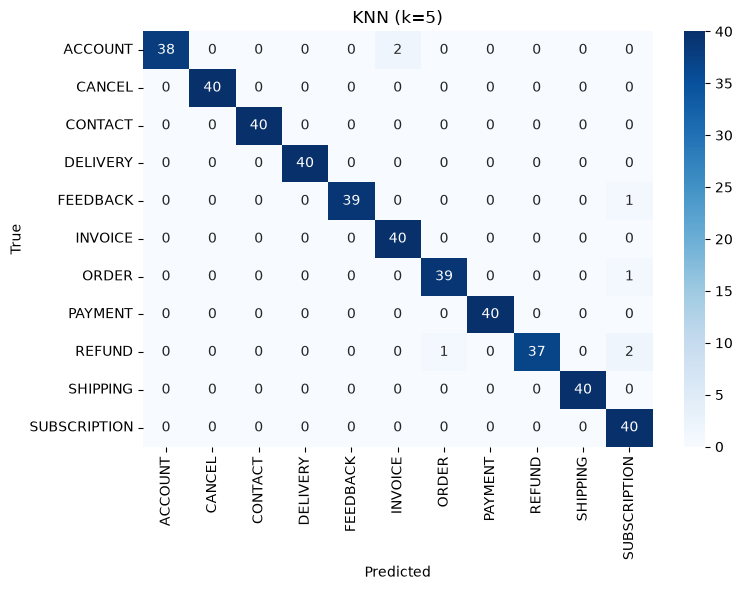

In [11]:
# 5. Confusion matrices
for name, (_, _, cm) in fitted.items():
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(name); plt.ylabel("True"); plt.xlabel("Predicted"); plt.tight_layout()
    plt.savefig(f"../outputs/cm_{name.split()[0]}.png", dpi=150); plt.show()

In [12]:
# 6. Errors of the chosen model
best = "MultinomialNB"
pipe, pred, _ = fitted[best]
print(classification_report(y_test, pred))
errs = pd.DataFrame({"message": X_test.values, "true": y_test.values, "pred": pred})
print(errs[errs.true != errs.pred])

              precision    recall  f1-score   support

     ACCOUNT       1.00      0.95      0.97        40
      CANCEL       1.00      1.00      1.00        40
     CONTACT       1.00      1.00      1.00        40
    DELIVERY       1.00      1.00      1.00        40
    FEEDBACK       1.00      1.00      1.00        40
     INVOICE       1.00      1.00      1.00        40
       ORDER       1.00      1.00      1.00        40
     PAYMENT       0.98      1.00      0.99        40
      REFUND       1.00      1.00      1.00        40
    SHIPPING       0.98      1.00      0.99        40
SUBSCRIPTION       1.00      1.00      1.00        40

    accuracy                           1.00       440
   macro avg       1.00      1.00      1.00       440
weighted avg       1.00      1.00      1.00       440

                                               message     true      pred
194  I don't know how I can inform of problems with...  ACCOUNT   PAYMENT
360       i do not know how to update m

In [13]:
# 7. Most important words per category (NB log-probabilities)
vec, nb = pipe.steps[0][1], pipe.steps[1][1]
words = np.array(vec.get_feature_names_out())
top = {c: list(words[np.argsort(nb.feature_log_prob_[i] - nb.feature_log_prob_.mean(axis=0))[-8:][::-1]])
       for i, c in enumerate(nb.classes_)}
pd.Series(top).to_csv("../outputs/top_words.csv")
for c, w in top.items(): print(c, w)

ACCOUNT ['account', 'type', 'signup', 'category', 'standard', 'profile', 'on', 'use']
CANCEL ['early', 'termination', 'withdrawal', 'fees', 'fee', 'exit', 'charge', 'cancellation']
CONTACT ['customer', 'speak', 'hours', 'agent', 'talk', 'support', 'contact', 'call']
DELIVERY ['arrive', 'soon', 'expect', 'when', 'options', 'shipment', 'delivery', 'shipping']
FEEDBACK ['feedback', 'against', 'claim', 'leave', 'complaint', 'lodge', 'consumer', 'file']
INVOICE ['bill', 'name', 'invoice', 'person', 'download', '00108', 'from', '37777']
ORDER ['order', 'number', 'purchase', 'some', 'several', 'articles', 'status', 'items']
PAYMENT ['payment', 'payments', 'online', 'options', 'with', 'list', 'accepted', 'inform']
REFUND ['money', 'refund', 'reimbursement', 'in', 'cases', 'request', 'rebate', 'back']
SHIPPING ['address', 'delivery', 'shipping', 'set', 'up', 'new', 'secondary', 'update']
SUBSCRIPTION ['newsletter', 'subscription', 'corporate', 'unsubscribe', 'company', 'receive', 'cancel', 'you

In [14]:
# 8. Robustness test: add typos to test messages (fairness check)
def add_typos(t, p=0.08):
    ch = list(t)
    for i in range(len(ch) - 1):
        if random.random() < p and ch[i].isalpha(): ch[i], ch[i+1] = ch[i+1], ch[i]
    return "".join(ch)
random.seed(1)
noisy = X_test.apply(add_typos)
for name in ["MultinomialNB", "DecisionTree", "RandomForest", "KNN (k=5)"]:
    print(name, "clean:", round(accuracy_score(y_test, fitted[name][0].predict(X_test)), 3),
          "noisy:", round(accuracy_score(y_test, fitted[name][0].predict(noisy)), 3))

MultinomialNB clean: 0.995 noisy: 0.898
DecisionTree clean: 0.941 noisy: 0.675
RandomForest clean: 0.986 noisy: 0.811
KNN (k=5) clean: 0.984 noisy: 0.836


In [15]:
# 9. Confidence threshold: send unsure messages to a human
proba = pipe.predict_proba(X_test).max(axis=1)
for t in [0.3, 0.5, 0.7]:
    keep = proba >= t
    print(f"threshold {t}: auto-routed {keep.mean():.0%}, accuracy on those {accuracy_score(y_test[keep], pred[keep]):.3f}")

threshold 0.3: auto-routed 99%, accuracy on those 0.998
threshold 0.5: auto-routed 91%, accuracy on those 1.000
threshold 0.7: auto-routed 71%, accuracy on those 1.000
